# DATASET EVENEMENTS

## 1. Chargement et vue d'ensemble

In [24]:
import pandas as pd 
import matplotlib.pyplot as plt
from scipy import stats

df_evenements = pd.read_csv('../data/raw/Dome_evenements.csv')

print(df_evenements.columns.tolist())

df_evenements.head()


['evenement_id', 'genre', 'jour_semaine', 'capacite', 'prix_moyen_eur', 'notoriete_artiste', 'billets_vendus', 'date']


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
0,EV320,rap,dim,9800,18.00,26.0,4923.0,2025-11-20
1,EV370,spectacle,mar,15800,74.23,20.0,6051.0,2026-06-08
2,EV377,sport,sam,6500,45.99,53.0,5221.0,2026-07-06
3,EV362,rap,ven,9800,70.96,NaN,6203.0,2026-05-07
4,EV394,sport,dim,9800,46.33,100.0,7196.0,2026-09-12


In [25]:
# Informations générales sur le dataset

print("Shape")
print(df_evenements.shape)

print("\n types des colonnes")
print(df_evenements.dtypes)

print("\n ====================================================================================================================================")


print("\n Stats descriptives")
df_evenements.describe()


Shape
(98, 8)

 types des colonnes
evenement_id             str
genre                    str
jour_semaine             str
capacite               int64
prix_moyen_eur       float64
notoriete_artiste    float64
billets_vendus       float64
date                     str
dtype: object


 Stats descriptives


,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus
count,98.000000,98.000000,96.000000,98.000000
mean,10510.204082,71.712143,42.000000,5512.989796
std,3557.321180,27.453541,28.302501,2020.345089
min,6500.000000,18.000000,5.000000,0.000000
25%,6500.000000,48.482500,21.000000,4354.750000
50%,9800.000000,73.115000,33.500000,5567.000000
75%,15800.000000,90.517500,56.750000,6500.000000
max,15800.000000,137.080000,100.000000,10179.000000


## 2. Valeurs manquantes et doublons

In [26]:
print("Etude de potentielles valeurs manquantes dans le dataset")
print("\n Valeurs manquantes")
display(df_evenements.isnull().sum().sort_values(ascending=False))


Etude de potentielles valeurs manquantes dans le dataset

 Valeurs manquantes


notoriete_artiste    2
evenement_id         0
jour_semaine         0
genre                0
capacite             0
prix_moyen_eur       0
billets_vendus       0
date                 0
dtype: int64

Seule `notoriete_artiste` est incomplète (2 valeurs manquantes sur 98, soit ≈ 2 %) ; les autres colonnes sont complètes, sous réserve des 3 valeurs à 0 de `billets_vendus` (voir plus bas).

In [27]:
print("Etude de potentiels doublons sur le dataset")

print("\n Doublons - lignes entières")
print(df_evenements.duplicated().sum())

print("\n Lignes concernées")
display(df_evenements[df_evenements.duplicated(keep=False)].sort_values(by='evenement_id'))

print("\n ====================================================================================================================================")


print("\n Doublons - même evenement_id")
print(df_evenements.duplicated(subset='evenement_id').sum())

print("\n Lignes concernées")
display(df_evenements[df_evenements.duplicated(subset='evenement_id', keep=False)].sort_values(by='evenement_id'))

print("\n ====================================================================================================================================")



colonnes_sans_id = df_evenements.columns.drop('evenement_id')

print("\n Doublons - même contenu, id différent")
print(df_evenements.duplicated(subset=colonnes_sans_id).sum())

print("\n Lignes concernées")
display(df_evenements[df_evenements.duplicated(subset=colonnes_sans_id, keep=False)].sort_values(by='date'))

Etude de potentiels doublons sur le dataset

 Doublons - lignes entières
2

 Lignes concernées


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
24,EV331,concert pop,jeu,6500,87.49,8.0,2185.0,2026-01-03
48,EV331,concert pop,jeu,6500,87.49,8.0,2185.0,2026-01-03
17,EV340,rock,jeu,15800,84.05,46.0,5567.0,2026-02-08
84,EV340,rock,jeu,15800,84.05,46.0,5567.0,2026-02-08




 Doublons - même evenement_id
2

 Lignes concernées


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
24,EV331,concert pop,jeu,6500,87.49,8.0,2185.0,2026-01-03
48,EV331,concert pop,jeu,6500,87.49,8.0,2185.0,2026-01-03
17,EV340,rock,jeu,15800,84.05,46.0,5567.0,2026-02-08
84,EV340,rock,jeu,15800,84.05,46.0,5567.0,2026-02-08




 Doublons - même contenu, id différent
2

 Lignes concernées


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
24,EV331,concert pop,jeu,6500,87.49,8.0,2185.0,2026-01-03
48,EV331,concert pop,jeu,6500,87.49,8.0,2185.0,2026-01-03
17,EV340,rock,jeu,15800,84.05,46.0,5567.0,2026-02-08
84,EV340,rock,jeu,15800,84.05,46.0,5567.0,2026-02-08


2 événements (EV331, EV340) sont présents en double à l’identique. Aucun identifiant n’est en conflit et aucun événement n’est saisi sous deux identifiants. Décision : supprimer les 2 copies lors du preprocessing (98 → 96 événements). 

## 3. Variables catégorielles

In [28]:
print("Etudes sur la colonne genre et jour de la semaine")

display(df_evenements['genre'].value_counts(dropna = False))
display(df_evenements['jour_semaine'].value_counts(dropna = False))


Etudes sur la colonne genre et jour de la semaine


genre
concert pop    28
rock           26
rap            14
sport          13
humour          9
spectacle       8
Name: count, dtype: int64

jour_semaine
sam    33
ven    17
jeu    16
mer    13
dim    11
mar     8
Name: count, dtype: int64

Les deux colonnes catégorielles sont propres : aucune valeur manquante, aucune écriture incohérente (effectifs calculés sur 98 lignes, doublons inclus). On retient les petits effectifs de humour et spectacle, la sur-représentation du samedi et l'absence du lundi dans `jour_semaine` ; cette colonne est incohérente avec la date (voir l'étude de la date).

## 4. Ventes et taux de remplissage

In [29]:
# A. Valeurs non entières
print("\n Valeurs non entières")
masque_non_entier = df_evenements['billets_vendus']!=df_evenements['billets_vendus'].round()
print(masque_non_entier.value_counts())
display(df_evenements[masque_non_entier])




 Valeurs non entières
billets_vendus
False    98
Name: count, dtype: int64


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date


billets_vendus est lue en float parce que le fichier écrit les valeurs avec un .0 ; les 98 valeurs sont entières, la colonne sera convertie en entier au preprocessing.

In [30]:
# B. Événements à 0 billet
print("\n Événements à 0 billet")
masque_zero = df_evenements['billets_vendus']== 0
print(masque_zero.value_counts())
display(df_evenements[masque_zero])


 Événements à 0 billet
billets_vendus
False    95
True      3
Name: count, dtype: int64


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
46,EV374,concert pop,sam,15800,103.45,17.0,0.0,2026-06-24
55,EV303,rock,sam,9800,48.11,NaN,0.0,2025-09-13
78,EV355,rock,sam,9800,87.13,14.0,0.0,2026-04-09


*Mise à jour : l'audit des billets montre 12, 7 et 6 billets pour ces événements ; le 0 est une valeur manquante (voir `eda_billets`, étape 7).*

In [31]:
# Vérifier qu'aucun événement ne vend plus de billets que sa capacité

print("\n Dépassement de capacité de salles")

masque_depassement= df_evenements['billets_vendus']>df_evenements['capacite']
print(masque_depassement.value_counts())
display(df_evenements[masque_depassement])



 Dépassement de capacité de salles
False    98
Name: count, dtype: int64


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date


Aucun événement ne dépasse sa capacité (0 sur 98).

In [32]:
# Etude de taux de remplissage des stades/salles

taux_de_remplissage = df_evenements['billets_vendus']/df_evenements['capacite']
taux_de_remplissage.describe()

count    98.000000
mean      0.560887
std       0.221163
min       0.000000
25%       0.401825
50%       0.551785
75%       0.678618
max       1.000000
dtype: float64

Le taux de remplissage moyen est de 56 % (médiane 55 %) ; la moitié des événements se remplit entre 40 % et 68 %

In [33]:
print("\n Événements complets (taux = 1)")
masque_complet = taux_de_remplissage == 1
print(masque_complet.value_counts())
display(df_evenements[masque_complet])


 Événements complets (taux = 1)
False    93
True      5
Name: count, dtype: int64


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
37,EV343,spectacle,sam,6500,88.32,74.0,6500.0,2026-02-20
70,EV324,humour,sam,6500,29.54,60.0,6500.0,2025-12-06
83,EV348,sport,sam,9800,21.34,100.0,9800.0,2026-03-12
93,EV383,concert pop,mer,6500,104.41,95.0,6500.0,2026-07-30
94,EV367,spectacle,sam,6500,45.86,38.0,6500.0,2026-05-27


5 événements sur 98 sont complets (EV343, EV324, EV348, EV383, EV367), dont 4 en petite configuration (6 500 places) et 4 annoncés un samedi dans `jour_semaine` ; leurs ventes sont plafonnées par la jauge et ne mesurent pas la demande réelle (à prendre en compte pour Q2 et Q3).

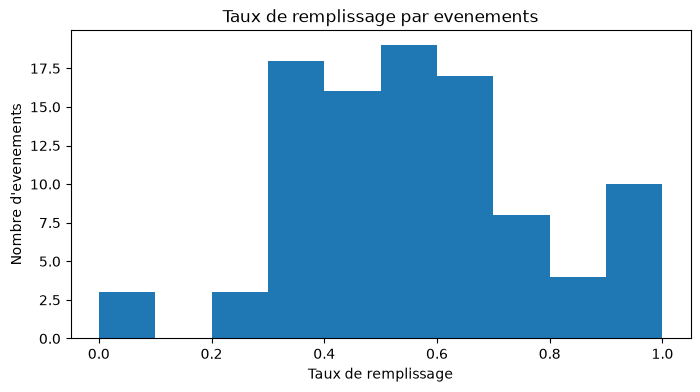

In [34]:

plt.figure(figsize=(8, 4))
plt.hist(taux_de_remplissage, bins=10)
plt.title("Taux de remplissage par evenements")
plt.xlabel("Taux de remplissage")
plt.ylabel("Nombre d'evenements")
plt.show()

Les 3 événements à 0 % sont isolés (aucun événement entre 10 et 20 %) ; la majorité se remplit entre 30 et 70 % ; une remontée vers 90-100 % traduit un effet plafond lié à la jauge.

In [35]:
print("\n Effet des événements à 0 billet sur le taux de remplissage")
print(" Moyenne avec les zéros :", round(taux_de_remplissage.mean(), 3))
print(" Moyenne sans les zéros :", round(taux_de_remplissage[taux_de_remplissage != 0].mean(), 3))
print(" Médiane avec les zéros :", round(taux_de_remplissage.median(), 3))
print(" Médiane sans les zéros :", round(taux_de_remplissage[taux_de_remplissage != 0].median(), 3))


 Effet des événements à 0 billet sur le taux de remplissage
 Moyenne avec les zéros : 0.561
 Moyenne sans les zéros : 0.579
 Médiane avec les zéros : 0.552
 Médiane sans les zéros : 0.557


Exclure les 3 zéros fait passer la moyenne de 56,1 % à 57,9 % et la médiane de 55,2 % à 55,7 % : l'impact global est faible, mais il est concentré sur le samedi et devra être pris en compte dans l'analyse par jour (Q1).

In [36]:
entrees_saison = 180000   # contexte du sujet : « 180 000 entrées »
nb_evenements = 100       # contexte du sujet : « près de 100 événements »

moyenne_contexte = entrees_saison / nb_evenements
moyenne_fichier = df_evenements['billets_vendus'].mean()
total_fichier = df_evenements['billets_vendus'].sum()

print("\n Cohérence avec le contexte du sujet")
print(" Entrées moyennes par événement (contexte) :", round(moyenne_contexte))
print(" Billets vendus moyens (fichier)           :", round(moyenne_fichier))
print(" Rapport fichier / contexte                :", round(moyenne_fichier / moyenne_contexte, 2))
print("\n Total entrées annoncé (contexte)          :", entrees_saison)
print(" Total billets vendus (fichier)            :", round(total_fichier))


 Cohérence avec le contexte du sujet
 Entrées moyennes par événement (contexte) : 1800
 Billets vendus moyens (fichier)           : 5513
 Rapport fichier / contexte                : 3.06

 Total entrées annoncé (contexte)          : 180000
 Total billets vendus (fichier)            : 540273


Le fichier donne en moyenne 3,06 fois plus de billets par événement que le contexte du sujet (540 273 contre 180 000 au total) ; écart non expliqué à ce stade, signalé et à confronter au fichier des billets.

## 5. Notoriété de l'artiste

In [37]:
print("\n Lignes avec notoriété manquante")
masque_notoriete_nan = df_evenements['notoriete_artiste'].isnull()
display(df_evenements[masque_notoriete_nan])


 Lignes avec notoriété manquante


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
3,EV362,rap,ven,9800,70.96,NaN,6203.0,2026-05-07
55,EV303,rock,sam,9800,48.11,NaN,0.0,2025-09-13


Les 2 notoriétés manquantes concernent EV362 (rap, 6 203 billets) et EV303 (rock, déjà à 0 billet). Décision : EV303 suivra la décision prise pour les événements à 0 billet ; pour EV362, imputation par la médiane de notoriété du genre rap, pour conserver l'événement sans biaiser l'échelle (la colonne est asymétrique, la médiane est plus robuste que la moyenne).

## 6. Date et cohérence avec le jour de la semaine

In [38]:
# Conversion dans une variable à part (on ne modifie pas df_evenements)
dates = pd.to_datetime(df_evenements['date'], errors='coerce')

print("\n Dates illisibles :", dates.isnull().sum())
print(" Première date :", dates.min().date())
print(" Dernière date :", dates.max().date())
print(" Durée couverte (jours) :", (dates.max() - dates.min()).days)


 Dates illisibles : 0
 Première date : 2025-09-01
 Dernière date : 2026-09-16
 Durée couverte (jours) : 380


Les dates vont du 01/09/2025 au 16/09/2026 (380 jours, soit une saison) ; aucune date illisible.

In [39]:
# Jour calculé à partir de la date, au même format que jour_semaine
noms_jours = {0: 'lun', 1: 'mar', 2: 'mer', 3: 'jeu', 4: 'ven', 5: 'sam', 6: 'dim'}
jour_calcule = dates.dt.day_of_week.map(noms_jours)

masque_jour_incoherent = jour_calcule != df_evenements['jour_semaine']
print("\n Incohérences date / jour_semaine")
print(masque_jour_incoherent.value_counts())

comparaison = df_evenements[['evenement_id', 'date', 'jour_semaine']].copy()
comparaison['jour_calcule'] = jour_calcule
display(comparaison[masque_jour_incoherent])


 Incohérences date / jour_semaine
True     81
False    17
Name: count, dtype: int64


,evenement_id,date,jour_semaine,jour_calcule
0,EV320,2025-11-20,dim,jeu
1,EV370,2026-06-08,mar,lun
2,EV377,2026-07-06,sam,lun
3,EV362,2026-05-07,ven,jeu
4,EV394,2026-09-12,dim,sam
...,...,...,...,...
91,EV357,2026-04-17,mer,ven
93,EV383,2026-07-30,mer,jeu
94,EV367,2026-05-27,sam,mer
95,EV325,2025-12-10,sam,mer


In [40]:
# Combien de concordances obtiendrait-on si jour_semaine était tiré au hasard ?
nb_concordances = (~masque_jour_incoherent).sum()
concordances_hasard = len(df_evenements) / 7

print("\n Concordances observées :", nb_concordances, "sur", len(df_evenements))
print(" Concordances attendues au hasard :", round(concordances_hasard, 1))


 Concordances observées : 17 sur 98
 Concordances attendues au hasard : 14.0


In [41]:
ordre_jours = ['lun', 'mar', 'mer', 'jeu', 'ven', 'sam', 'dim']

repartition = pd.DataFrame({
    'jour_semaine (saisi)': df_evenements['jour_semaine'].value_counts(),
    'jour_calcule (date)': jour_calcule.value_counts()
}).reindex(ordre_jours).fillna(0).astype(int)

print("\n Répartition des événements par jour")
display(repartition)


 Répartition des événements par jour


,jour_semaine (saisi),jour_calcule (date)
lun,0,14
mar,8,14
mer,13,14
jeu,16,13
ven,17,14
sam,33,15
dim,11,14


In [42]:
evenements_a_suivre = masque_zero | masque_complet

suivi = df_evenements.loc[evenements_a_suivre, ['evenement_id', 'date', 'jour_semaine', 'billets_vendus', 'capacite']].copy()
suivi['jour_calcule'] = jour_calcule[evenements_a_suivre]

print("\n Événements à 0 billet et complets : jour saisi vs jour calculé")
display(suivi)


 Événements à 0 billet et complets : jour saisi vs jour calculé


,evenement_id,date,jour_semaine,billets_vendus,capacite,jour_calcule
37,EV343,2026-02-20,sam,6500.0,6500,ven
46,EV374,2026-06-24,sam,0.0,15800,mer
55,EV303,2025-09-13,sam,0.0,9800,sam
70,EV324,2025-12-06,sam,6500.0,6500,sam
78,EV355,2026-04-09,sam,0.0,9800,jeu
83,EV348,2026-03-12,sam,9800.0,9800,jeu
93,EV383,2026-07-30,mer,6500.0,6500,jeu
94,EV367,2026-05-27,sam,6500.0,6500,mer


In [43]:
comparaison_taux = pd.DataFrame({
    'taux moyen (jour saisi)': taux_de_remplissage.groupby(df_evenements['jour_semaine']).mean(),
    'nb (jour saisi)': df_evenements['jour_semaine'].value_counts(),
    'taux moyen (jour calculé)': taux_de_remplissage.groupby(jour_calcule).mean(),
    'nb (jour calculé)': jour_calcule.value_counts()
}).reindex(ordre_jours).round(3)

print("\n Taux de remplissage moyen par jour : jour saisi vs jour calculé")
display(comparaison_taux)

print("\n Écart entre le meilleur et le pire jour")
print(" Jour saisi   :", round(comparaison_taux['taux moyen (jour saisi)'].max() - comparaison_taux['taux moyen (jour saisi)'].min(), 3))
print(" Jour calculé :", round(comparaison_taux['taux moyen (jour calculé)'].max() - comparaison_taux['taux moyen (jour calculé)'].min(), 3))


 Taux de remplissage moyen par jour : jour saisi vs jour calculé


,taux moyen (jour saisi),nb (jour saisi),taux moyen (jour calculé),nb (jour calculé)
lun,NaN,NaN,0.624,14
mar,0.465,8.0,0.545,14
mer,0.588,13.0,0.562,14
jeu,0.546,16.0,0.637,13
ven,0.581,17.0,0.585,14
sam,0.600,33.0,0.486,15
dim,0.473,11.0,0.498,14



 Écart entre le meilleur et le pire jour
 Jour saisi   : 0.135
 Jour calculé : 0.151


In [44]:

groupes_saisi = [taux_de_remplissage[df_evenements['jour_semaine'] == j] for j in df_evenements['jour_semaine'].unique()]
groupes_calcule = [taux_de_remplissage[jour_calcule == j] for j in jour_calcule.unique()]

stat_saisi, p_saisi = stats.kruskal(*groupes_saisi)
stat_calcule, p_calcule = stats.kruskal(*groupes_calcule)

print("\n Test de Kruskal-Wallis : le taux de remplissage dépend-il du jour ?")
print(" Jour saisi   : p-value =", round(p_saisi, 4))
print(" Jour calculé : p-value =", round(p_calcule, 4))


 Test de Kruskal-Wallis : le taux de remplissage dépend-il du jour ?
 Jour saisi   : p-value = 0.2219
 Jour calculé : p-value = 0.1901


Seuls 17 événements sur 98 ont un `jour_semaine` cohérent avec leur date (≈ 14 attendus au hasard) : les deux colonnes sont sans lien. Selon la date, les événements se répartissent uniformément sur les 7 jours (13 à 15 par jour, lundi compris), ce qui est peu plausible pour une salle de spectacle ; `jour_semaine` présente au contraire un profil réaliste (samedi dominant, aucun lundi). Un test de Kruskal-Wallis sur le taux de remplissage ne permet de départager aucune des deux colonnes (p = 0,22 pour le jour saisi, p = 0,19 pour le jour calculé). Décision : `jour_semaine` est retenu pour l'analyse par jour (Q1) sur le critère de plausibilité ; `date` sert uniquement à situer l'événement dans la saison. Ce choix sera signalé comme une limite.

## 7. Prix et capacité

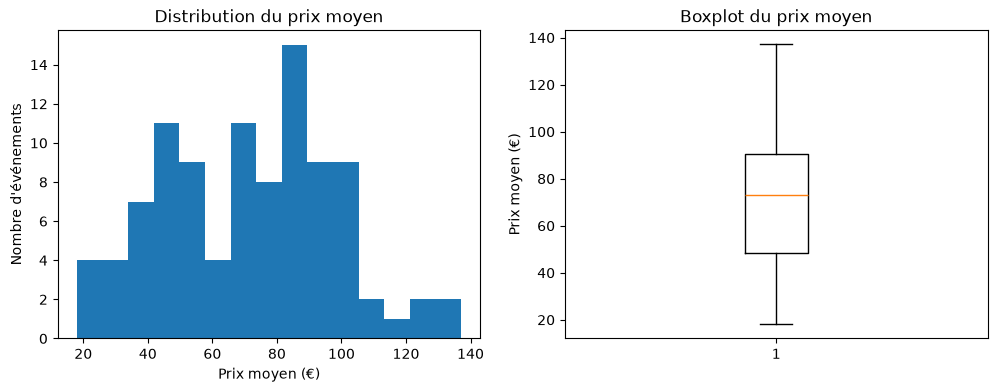


 Prix les plus bas


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
0,EV320,rap,dim,9800,18.00,26.0,4923.0,2025-11-20
49,EV316,humour,ven,6500,18.00,51.0,5725.0,2025-11-04
47,EV329,concert pop,sam,9800,18.43,44.0,6904.0,2025-12-26
83,EV348,sport,sam,9800,21.34,100.0,9800.0,2026-03-12
22,EV358,sport,sam,9800,26.86,37.0,4185.0,2026-04-21



 Prix les plus hauts


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date
13,EV312,concert pop,mar,9800,117.80,61.0,5523.0,2025-10-19
35,EV332,concert pop,sam,15800,127.92,32.0,7912.0,2026-01-07
67,EV361,humour,sam,9800,129.09,31.0,6254.0,2026-05-03
20,EV302,spectacle,sam,9800,136.79,33.0,3639.0,2025-09-09
56,EV335,rap,dim,9800,137.08,26.0,4489.0,2026-01-19


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_evenements['prix_moyen_eur'], bins=15)
axes[0].set_title("Distribution du prix moyen")
axes[0].set_xlabel("Prix moyen (€)")
axes[0].set_ylabel("Nombre d'événements")

axes[1].boxplot(df_evenements['prix_moyen_eur'])
axes[1].set_title("Boxplot du prix moyen")
axes[1].set_ylabel("Prix moyen (€)")

plt.show()

print("\n Prix les plus bas")
display(df_evenements.sort_values(by='prix_moyen_eur').head())
print("\n Prix les plus hauts")
display(df_evenements.sort_values(by='prix_moyen_eur').tail())

Le prix moyen va de 18 € à 137 € (médiane 73 €, moitié des événements entre 48 € et 90 €) ; aucune valeur isolée sur le boxplot et un ordre de grandeur cohérent avec des euros : aucune correction nécessaire.

In [46]:
print("\n Configurations de salle")
display(df_evenements['capacite'].value_counts())


 Configurations de salle


capacite
9800     43
6500     28
15800    27
Name: count, dtype: int64

La capacité ne prend que 3 valeurs (9 800 : 43 événements, 6 500 : 28, 15 800 : 27, doublons inclus) : ce sont des configurations de salle, à traiter comme une variable catégorielle dans les analyses.

## 8. Récapitulatif — Dome_evenements



| Problème | Constat | Décision | Justification |
|---|---|---|---|
| Doublons | 2 lignes identiques (EV331, EV340) | Supprimer les copies (98 → 96) | Même événement compté deux fois |
| Type de billets_vendus | float, valeurs toutes entières | Convertir en entier | Format d'export, aucune perte |
| Notoriété manquante | 2 valeurs (EV362, EV303) | EV362 : médiane du genre ; EV303 : voir 0 billet | Conserver l'événement sans biaiser l'échelle |
| 0 billet vendu | 3 événements (EV374, EV303, EV355) | Reportée → résolue dans l'audit des billets (étape 7) | À croiser avec le fichier des billets |
| Dépassement de capacité | 0 sur 98 | Aucune | Ventes cohérentes avec la jauge |
| Événements complets | 5 événements, dont 4 en 6 500 places | Conserver, signaler | Effet plafond pour Q2 et Q3 |
| Date / jour_semaine | 81 incohérences sur 98 (≈ hasard) | Retenir jour_semaine pour Q1 | Profil plausible ; date uniforme sur 7 jours ; test non concluant (p = 0,22 / 0,19) |
| Plage de dates | 01/09/2025 au 16/09/2026, aucune date illisible | Aucune | Une saison couverte |
| Écart avec le contexte | Facteur 3,06 (540 273 contre 180 000) | Signaler | Non expliqué à ce stade |
| Prix | 18 € à 137 €, aucune valeur isolée | Aucune | Valeurs plausibles en euros |
| Capacité | 3 configurations (6 500 / 9 800 / 15 800) | Traiter comme catégorielle | Ce sont des jauges, pas une variable continue |
| Genre et jour (catégories) | Aucune valeur manquante ni écriture incohérente | Aucune | Colonnes propres |